# MSc Final Project: Visible In-Progress (VIP) notebook

| | |
|---|---|
| **Project title** | *Multimodal Brain Tumour Classification Using MRI and CT Images* |
| **Student name / number** | *Niharika Rayavarapu / 24175430* |
| **Supervisor** | *Wajih Islam* |
| **GitHub repository** | *https://github.com/Niharika1003/msc-project-rayavarapu* |
| **Overleaf project** | *link to your IPR/FPR report* |
| **Ethics approval** | *Not required (reason) / Approved: ethics number* |

This notebook is your **practical work**: data, artefact, experiments and results. Your **report** (IPR 10%, FPR 70%) is written in the Overleaf template. Your **demo/viva (20%)** is run from this notebook.


1. **Add your supervisor as a collaborator** on your GitHub repository in week 1 (Settings → Collaborators → Add people). Your supervisor cannot review your work without this access.
2. **Commit and push after every task, after every change, and whenever you change an existing solution.** Your history shows how your project developed.
```bash
git status
git add .
git commit -m "CODE: what you did"
git push
```
3. Start each commit message with the part you worked on: `DATA:` · `CODE:` · `EXP:` · `TEST:` · `RESULT:` · `FIX:`
   e.g. `FIX: changed learning rate from 0.01 to 0.001, accuracy up to 0.87`
4. **Develop at least two parts of your artefact on their own branches** (for example your baseline and your proposed method). See *Working on a branch* below.
5. **Before each supervision meeting**, push your latest work. Your supervisor reviews what changed.
6. Never commit personal data or data that needs ethics approval. Keep the repository private, and do not rewrite its history.

## Working on a branch

A branch lets you build one part of your project without breaking the working version on `main`. Develop **at least two parts** this way, e.g. `baseline` and `proposed-method`.

**1. Create a branch and work on it**
```bash
git checkout -b baseline
```
Commit as usual while you work:
```bash
git status
git add .
git commit -m "CODE: baseline model, first version"
git push -u origin baseline
```
(`-u origin baseline` is needed only the first time you push a new branch.)

**2. When the part works, merge it into `main`**
```bash
git checkout main
git merge baseline
git push
```

**3. Start the next part on a new branch**
```bash
git checkout -b proposed-method
```

Check which branch you are on with `git branch` (the current one has a `*`). On GitHub, your supervisor can see every branch and its commits.

# Imports

In [36]:
# Essential libraries
import os
from pathlib import Path
# Data handling
import numpy as np
import pandas as pd
# Medical image processing
import nibabel as nib
# Visualisation
import matplotlib.pyplot as plt
# Machine learning
import sklearn
import tensorflow as tf
# Display settings
pd.set_option("display.max_columns", None)
print("All libraries imported successfully!")
print("TensorFlow version:", tf.__version__)

All libraries imported successfully!
TensorFlow version: 2.21.0


Save your work, then run these commands in the terminal:
```bash
git status
git add .
git commit -m "CODE: project set-up, folders and environment"
git push
```

# Research question and objectives

**Problem:** *Brain tumour classification using medical images can be challenging because different tumour types may have different imaging characteristics. MRI and CT provide different types of information about the brain.*

**Main research question:** *How effectively can deep learning techniques classify different types of brain tumours using MRI and CT images, individually and in combination?*

**Sub-questions:**
*1.How can MRI and CT images be preprocessed for deep learning classification?*

*2.How effectively can a 2D CNN classify brain tumour types using MRI images?*

*3.How does classification performance differ between MRI-only and CT-only models?*

*4.Can combining MRI and CT improve classification performance?*

**Objectives (specific and measurable):**
*1.Explore and understand a paired MRI–CT brain imaging dataset.*

*2.Develop a consistent preprocessing pipeline for MRI and CT images.*

*3.Develop a baseline 2D CNN for MRI-based tumour classification.*

*4.Investigate CT-based classification.*

*5.Develop a multimodal classification approach combining MRI and CT.*

*6.Compare the models using accuracy, precision, recall and F1-score.*


# Data
*FPR: Methodology*

**Source and licence:** ...

**Ethics / GDPR:** does the data include people or personal information? How is it stored and protected?

In [37]:
groups = {
    "meningioma": r"C:\Users\nihar\Downloads\meningioma\meningioma",

    "cerebrovascular disease": r"C:\Users\nihar\Downloads\cerebrovascular-disease\cerebrovascular-disease",

    "vestibular schwannoma": r"C:\Users\nihar\Downloads\vestibular-schwannoma (1)\vestibular-schwannoma",

    "pituitary tumor": r"C:\Users\nihar\Downloads\pituitary-tumor\pituitary-tumor"
}

In [38]:
from pathlib import Path

for diagnosis, folder_path in groups.items():
    folder = Path(folder_path)
    print(diagnosis, ":", folder.exists())

meningioma : True
cerebrovascular disease : True
vestibular schwannoma : True
pituitary tumor : True


In [39]:
from pathlib import Path
import pandas as pd

records = []

for diagnosis, folder_path in groups.items():

    folder = Path(folder_path)

    for file in folder.rglob("*"):
        if file.is_file() and (
            file.name.endswith(".nii") or
            file.name.endswith(".nii.gz")
        ):

            records.append({
                "Diagnosis": diagnosis,
                "File Name": file.name,
                "File Path": str(file)
            })

# Create DataFrame
df = pd.DataFrame(records)

print("Dataset shape:", df.shape)

display(df.head(10))

print("\nFiles per diagnosis:")
display(df.groupby("Diagnosis").size().reset_index(name="Total Files"))

Dataset shape: (420, 3)


,Diagnosis,File Name,File Path
0,meningioma,CE-T1W.nii.gz,C:\Users\nihar\Downloads\meningioma\meningioma...
1,meningioma,CT-BONE.nii.gz,C:\Users\nihar\Downloads\meningioma\meningioma...
2,meningioma,CT-BRAIN.nii.gz,C:\Users\nihar\Downloads\meningioma\meningioma...
3,meningioma,CE-T1W.nii.gz,C:\Users\nihar\Downloads\meningioma\meningioma...
4,meningioma,CT-BONE.nii.gz,C:\Users\nihar\Downloads\meningioma\meningioma...
5,meningioma,CT-BRAIN.nii.gz,C:\Users\nihar\Downloads\meningioma\meningioma...
6,meningioma,CE-T1W.nii.gz,C:\Users\nihar\Downloads\meningioma\meningioma...
7,meningioma,CT-BONE.nii.gz,C:\Users\nihar\Downloads\meningioma\meningioma...
8,meningioma,CT-BRAIN.nii.gz,C:\Users\nihar\Downloads\meningioma\meningioma...
9,meningioma,CE-T1W.nii.gz,C:\Users\nihar\Downloads\meningioma\meningioma...



Files per diagnosis:


,Diagnosis,Total Files
0,cerebrovascular disease,60
1,meningioma,60
2,pituitary tumor,240
3,vestibular schwannoma,60


### Data-quality check and cleaning log

| Step | Problem found | What I changed | Why |
|---|---|---|---|
| 1 | The downloaded dataset contained four categories, including cerebrovascular disease.|Excluded cerebrovascular disease and selected the three tumour categories.| The project focuses on three brain tumour types.|
| 2 | Multiple NIfTI files were available for each patient.|Identified and organised CE-T1W MRI, NCE-T1W MRI, CT-BONE and CT-BRAIN files separately.| To identify the required imaging modalities for each patient.|
| 3 | MRI and CT scans need to be matched by patient.|Created a patient-level master table using diagnosis and patient ID, including a unique patient identifier. | To associate the MRI and CT scans belonging to each dataset patient.|
| 4 |Some patients did not have every scan type .|Checked scan availability for all 100 patients. All had CE-T1W MRI and CT-BRAIN; NCE-T1W was unavailable for 40 patients. |To identify missing modalities and select consistently available scans. |
| 5 |Image volumes had different dimensions and voxel spacing.|Audited image dimensions, voxel spacing and orientation for the selected MRI and CT scans. |To understand image geometry before preprocessing.|
| 6 |Some images contained different numerical characteristics or potentially invalid values.|Checked for NaN values, infinite values and all-zero images across 200 selected scans.|To identify basic numerical data-quality issues. |
| 7 |Two MRI–CT pairs had different affine matrices initially.|Investigated the two pairs and applied canonical orientation standardisation.|To standardise image orientation before further analysis. |
| 8 |MRI and CT geometry needed to be compared after standardisation.|Rechecked canonical orientation and affine matrices. All 100 pairs had matching orientation codes and affine matrices. |To verify consistency of their voxel-to-world geometry metadata. |
| 9 |Full 3D volumes required substantial memory for slice extraction.|Developed memory-efficient extraction code and extracted five 2D MRI slices per patient. |To begin preparing MRI data for 2D classification. |
| 10 |Extracted MRI slices needed visual inspection.|Displayed representative slices and compared examples from all three tumour categories. |Displayed representative slices and compared examples from all three tumour categories.|

In [40]:
# cleaning steps
# Step 1: Remove cerebrovascular disease

tumour_df = df[
    df["Diagnosis"] != "cerebrovascular disease"
].copy()

# Step 2: Check remaining categories

print("Remaining tumour categories:")
print(tumour_df["Diagnosis"].unique())

# Step 3: Check total files

print("\nTotal tumour NIfTI files:", len(tumour_df))

# Step 4: Check files per category

display(
    tumour_df.groupby("Diagnosis")
    .size()
    .reset_index(name="Total Files")
)

Remaining tumour categories:
<StringArray>
['meningioma', 'vestibular schwannoma', 'pituitary tumor']
Length: 3, dtype: str

Total tumour NIfTI files: 360


,Diagnosis,Total Files
0,meningioma,60
1,pituitary tumor,240
2,vestibular schwannoma,60


In [41]:
tumour_df["Scan Type"] = tumour_df["File Name"].apply(
    lambda x: (
        "MRI" if "CE-T1W" in x
        else "CT-BONE" if "CT-BONE" in x
        else "CT-BRAIN" if "CT-BRAIN" in x
        else "Other"
    )
)

scan_summary = (
    tumour_df.groupby(["Diagnosis", "Scan Type"])
    .size()
    .reset_index(name="Count")
)

display(scan_summary)

,Diagnosis,Scan Type,Count
0,meningioma,CT-BONE,20
1,meningioma,CT-BRAIN,20
2,meningioma,MRI,20
3,pituitary tumor,CT-BONE,60
4,pituitary tumor,CT-BRAIN,60
5,pituitary tumor,MRI,120
6,vestibular schwannoma,CT-BONE,20
7,vestibular schwannoma,CT-BRAIN,20
8,vestibular schwannoma,MRI,20


In [42]:
from pathlib import Path

for diagnosis, folder_path in groups.items():

    if diagnosis == "cerebrovascular disease":
        continue

    folder = Path(folder_path)

    patient_folders = [
        p for p in folder.iterdir()
        if p.is_dir()
    ]

    print(
        diagnosis,
        "Number of patient folders:",
        len(patient_folders)
    )

meningioma Number of patient folders: 20
vestibular schwannoma Number of patient folders: 20
pituitary tumor Number of patient folders: 60


In [43]:
from pathlib import Path

pituitary_folder = Path(groups["pituitary tumor"])

# Select the first patient folder
patient_folder = sorted(
    [p for p in pituitary_folder.iterdir() if p.is_dir()]
)[0]

print("Patient folder:", patient_folder.name)
print("\nFiles inside this patient folder:")

for file in sorted(patient_folder.rglob("*")):
    if file.is_file() and (
        file.name.endswith(".nii") or
        file.name.endswith(".nii.gz")
    ):
        print(file.name)

Patient folder: sub-01

Files inside this patient folder:
CE-T1W.nii.gz
CT-BONE.nii.gz
CT-BRAIN.nii.gz
NCE-T1W.nii.gz


In [44]:
pituitary_folder = Path(groups["pituitary tumor"])

patient_summary = []

for patient in sorted(p for p in pituitary_folder.iterdir() if p.is_dir()):

    files = [
        f.name for f in patient.rglob("*")
        if f.is_file() and (
            f.name.endswith(".nii") or
            f.name.endswith(".nii.gz")
        )
    ]

    patient_summary.append({
        "Patient ID": patient.name,
        "CE-T1W MRI": "CE-T1W.nii.gz" in files,
        "NCE-T1W MRI": "NCE-T1W.nii.gz" in files,
        "CT-BONE": "CT-BONE.nii.gz" in files,
        "CT-BRAIN": "CT-BRAIN.nii.gz" in files,
        "Total files": len(files)
    })

pituitary_summary = pd.DataFrame(patient_summary)

display(pituitary_summary)
display(
    pituitary_summary.groupby(
        ["CE-T1W MRI", "NCE-T1W MRI", "CT-BONE", "CT-BRAIN"]
    ).size().reset_index(name="Number of patients")
)

,Patient ID,CE-T1W MRI,NCE-T1W MRI,CT-BONE,CT-BRAIN,Total files
0,sub-01,True,True,True,True,4
1,sub-02,True,True,True,True,4
2,sub-03,True,True,True,True,4
3,sub-04,True,True,True,True,4
4,sub-05,True,True,True,True,4
5,sub-06,True,True,True,True,4
6,sub-07,True,True,True,True,4
7,sub-08,True,True,True,True,4
8,sub-09,True,True,True,True,4
9,sub-10,True,True,True,True,4


,CE-T1W MRI,NCE-T1W MRI,CT-BONE,CT-BRAIN,Number of patients
0,True,True,True,True,60


In [45]:
for diagnosis in ["meningioma", "vestibular schwannoma"]:

    folder = Path(groups[diagnosis])

    records = []

    for patient in sorted(p for p in folder.iterdir() if p.is_dir()):

        files = [
            f.name for f in patient.rglob("*")
            if f.is_file() and f.name.endswith((".nii", ".nii.gz"))
        ]

        records.append({
            "Diagnosis": diagnosis,
            "Patient": patient.name,
            "CE-T1W": any("CE-T1W" in f for f in files),
            "NCE-T1W": any("NCE-T1W" in f for f in files),
            "CT-BONE": any("CT-BONE" in f for f in files),
            "CT-BRAIN": any("CT-BRAIN" in f for f in files)
        })

    result = pd.DataFrame(records)

    print("\n", diagnosis)
    display(
        result.groupby(
            ["CE-T1W", "NCE-T1W", "CT-BONE", "CT-BRAIN"]
        ).size().reset_index(name="Number of patients")
    )


 meningioma


,CE-T1W,NCE-T1W,CT-BONE,CT-BRAIN,Number of patients
0,True,False,True,True,20



 vestibular schwannoma


,CE-T1W,NCE-T1W,CT-BONE,CT-BRAIN,Number of patients
0,True,False,True,True,20


Save your work, then run these commands in the terminal:
```bash
git status
git add .
git commit -m "DATA: cleaned dataset, see cleaning log"
git push
```

In [46]:
from pathlib import Path
import pandas as pd

records = []

# Process only the three tumour categories
for diagnosis in [
    "meningioma",
    "pituitary tumor",
    "vestibular schwannoma"
]:

    folder = Path(groups[diagnosis])

    # Go through each patient folder
    for patient in sorted(p for p in folder.iterdir() if p.is_dir()):

        files = list(patient.rglob("*.nii*"))

        # Find the required scan paths
        scan_paths = {}

        for scan in files:
            name = scan.name

            if name.startswith("CE-T1W"):
                scan_paths["CE-T1W MRI"] = str(scan)

            elif name.startswith("NCE-T1W"):
                scan_paths["NCE-T1W MRI"] = str(scan)

            elif name.startswith("CT-BONE"):
                scan_paths["CT-BONE"] = str(scan)

            elif name.startswith("CT-BRAIN"):
                scan_paths["CT-BRAIN"] = str(scan)

        records.append({
            "Diagnosis": diagnosis,
            "Patient ID": patient.name,
            "CE-T1W MRI": scan_paths.get("CE-T1W MRI"),
            "NCE-T1W MRI": scan_paths.get("NCE-T1W MRI"),
            "CT-BONE": scan_paths.get("CT-BONE"),
            "CT-BRAIN": scan_paths.get("CT-BRAIN")
        })

# Create master DataFrame
master_df = pd.DataFrame(records)

# Sort records
master_df = master_df.sort_values(
    ["Diagnosis", "Patient ID"]
).reset_index(drop=True)

print("Master dataset shape:", master_df.shape)

display(master_df.head(10))
print("Total patients:", len(master_df))

print("\nPatients by diagnosis:")

display(
    master_df.groupby("Diagnosis")
    .size()
    .reset_index(name="Number of patients")
)

Master dataset shape: (100, 6)


,Diagnosis,Patient ID,CE-T1W MRI,NCE-T1W MRI,CT-BONE,CT-BRAIN
0,meningioma,sub-01,C:\Users\nihar\Downloads\meningioma\meningioma...,NaN,C:\Users\nihar\Downloads\meningioma\meningioma...,C:\Users\nihar\Downloads\meningioma\meningioma...
1,meningioma,sub-02,C:\Users\nihar\Downloads\meningioma\meningioma...,NaN,C:\Users\nihar\Downloads\meningioma\meningioma...,C:\Users\nihar\Downloads\meningioma\meningioma...
2,meningioma,sub-03,C:\Users\nihar\Downloads\meningioma\meningioma...,NaN,C:\Users\nihar\Downloads\meningioma\meningioma...,C:\Users\nihar\Downloads\meningioma\meningioma...
3,meningioma,sub-04,C:\Users\nihar\Downloads\meningioma\meningioma...,NaN,C:\Users\nihar\Downloads\meningioma\meningioma...,C:\Users\nihar\Downloads\meningioma\meningioma...
4,meningioma,sub-05,C:\Users\nihar\Downloads\meningioma\meningioma...,NaN,C:\Users\nihar\Downloads\meningioma\meningioma...,C:\Users\nihar\Downloads\meningioma\meningioma...
5,meningioma,sub-06,C:\Users\nihar\Downloads\meningioma\meningioma...,NaN,C:\Users\nihar\Downloads\meningioma\meningioma...,C:\Users\nihar\Downloads\meningioma\meningioma...
6,meningioma,sub-07,C:\Users\nihar\Downloads\meningioma\meningioma...,NaN,C:\Users\nihar\Downloads\meningioma\meningioma...,C:\Users\nihar\Downloads\meningioma\meningioma...
7,meningioma,sub-08,C:\Users\nihar\Downloads\meningioma\meningioma...,NaN,C:\Users\nihar\Downloads\meningioma\meningioma...,C:\Users\nihar\Downloads\meningioma\meningioma...
8,meningioma,sub-09,C:\Users\nihar\Downloads\meningioma\meningioma...,NaN,C:\Users\nihar\Downloads\meningioma\meningioma...,C:\Users\nihar\Downloads\meningioma\meningioma...
9,meningioma,sub-10,C:\Users\nihar\Downloads\meningioma\meningioma...,NaN,C:\Users\nihar\Downloads\meningioma\meningioma...,C:\Users\nihar\Downloads\meningioma\meningioma...


Total patients: 100

Patients by diagnosis:


,Diagnosis,Number of patients
0,meningioma,20
1,pituitary tumor,60
2,vestibular schwannoma,20


In [47]:
scan_columns = [
    "CE-T1W MRI",
    "NCE-T1W MRI",
    "CT-BONE",
    "CT-BRAIN"
]

print("Missing scans:")

display(master_df[scan_columns].isnull().sum())

Missing scans:


CE-T1W MRI      0
NCE-T1W MRI    40
CT-BONE         0
CT-BRAIN        0
dtype: int64

In [48]:
master_df["Unique Patient ID"] = (
    master_df["Diagnosis"] + "_" + master_df["Patient ID"]
)

print("Total unique patients:", master_df["Unique Patient ID"].nunique())

display(
    master_df[
        ["Diagnosis", "Patient ID", "Unique Patient ID"]
    ].head(10)
)

Total unique patients: 100


,Diagnosis,Patient ID,Unique Patient ID
0,meningioma,sub-01,meningioma_sub-01
1,meningioma,sub-02,meningioma_sub-02
2,meningioma,sub-03,meningioma_sub-03
3,meningioma,sub-04,meningioma_sub-04
4,meningioma,sub-05,meningioma_sub-05
5,meningioma,sub-06,meningioma_sub-06
6,meningioma,sub-07,meningioma_sub-07
7,meningioma,sub-08,meningioma_sub-08
8,meningioma,sub-09,meningioma_sub-09
9,meningioma,sub-10,meningioma_sub-10


# Exploratory analysis
*FPR: Methodology; Quality and Results*

*What did you learn from the data, and how does it affect your method?*

Save your work, then run these commands in the terminal:
```bash
git status
git add .
git commit -m "CODE: baseline and proposed method"
git push
```

In [49]:
import nibabel as nib
import numpy as np

# Inspect the first patient's scans
sample = master_df.iloc[0]

scan_paths = {
    "CE-T1W MRI": sample["CE-T1W MRI"],
    "CT-BONE": sample["CT-BONE"],
    "CT-BRAIN": sample["CT-BRAIN"]
}

for scan_name, file_path in scan_paths.items():

    image = nib.load(file_path)

    print("\nScan:", scan_name)
    print("Image dimensions:", image.shape)
    print("Voxel spacing (mm):", nib.affines.voxel_sizes(image.affine))
    print("Orientation:", nib.aff2axcodes(image.affine))


Scan: CE-T1W MRI
Image dimensions: (440, 440, 381)
Voxel spacing (mm): [0.5 0.5 0.5]
Orientation: ('L', 'A', 'S')

Scan: CT-BONE
Image dimensions: (440, 440, 381)
Voxel spacing (mm): [0.5 0.5 0.5]
Orientation: ('L', 'A', 'S')

Scan: CT-BRAIN
Image dimensions: (440, 440, 381)
Voxel spacing (mm): [0.5 0.5 0.5]
Orientation: ('L', 'A', 'S')


In [50]:
import nibabel as nib
import pandas as pd

image_records = []

for _, row in master_df.iterrows():

    scans = {
        "CE-T1W MRI": row["CE-T1W MRI"],
        "CT-BONE": row["CT-BONE"],
        "CT-BRAIN": row["CT-BRAIN"]
    }

    for scan_name, file_path in scans.items():

        image = nib.load(file_path)

        image_records.append({
            "Diagnosis": row["Diagnosis"],
            "Patient ID": row["Patient ID"],
            "Scan Type": scan_name,
            "Dimensions": image.shape,
            "Voxel Spacing": tuple(
                nib.affines.voxel_sizes(image.affine)
            ),
            "Orientation": nib.aff2axcodes(image.affine)
        })

image_df = pd.DataFrame(image_records)

print("Total image records:", len(image_df))

display(image_df.head(300))

Total image records: 300


,Diagnosis,Patient ID,Scan Type,Dimensions,Voxel Spacing,Orientation
0,meningioma,sub-01,CE-T1W MRI,"(440, 440, 381)","(0.5, 0.5, 0.5)","(L, A, S)"
1,meningioma,sub-01,CT-BONE,"(440, 440, 381)","(0.5, 0.5, 0.5)","(L, A, S)"
2,meningioma,sub-01,CT-BRAIN,"(440, 440, 381)","(0.5, 0.5, 0.5)","(L, A, S)"
3,meningioma,sub-02,CE-T1W MRI,"(440, 440, 381)","(0.5, 0.5, 0.5)","(L, A, S)"
4,meningioma,sub-02,CT-BONE,"(440, 440, 381)","(0.5, 0.5, 0.5)","(L, A, S)"
...,...,...,...,...,...,...
295,vestibular schwannoma,sub-19,CT-BONE,"(378, 378, 321)","(0.5, 0.5, 0.5)","(L, P, S)"
296,vestibular schwannoma,sub-19,CT-BRAIN,"(378, 378, 321)","(0.5, 0.5, 0.5)","(L, P, S)"
297,vestibular schwannoma,sub-20,CE-T1W MRI,"(440, 440, 361)","(0.5, 0.5, 0.5)","(L, P, S)"
298,vestibular schwannoma,sub-20,CT-BONE,"(440, 440, 361)","(0.5, 0.5, 0.5)","(L, P, S)"


In [51]:
# Keep only our selected modalities

selected_image_df = image_df[
    image_df["Scan Type"].isin(
        ["CE-T1W MRI", "CT-BRAIN"]
    )
].copy()

print("Selected image records:", len(selected_image_df))

print("\nImage dimensions:")
display(
    selected_image_df["Dimensions"]
    .value_counts()
    .reset_index()
)

print("\nVoxel spacing:")
display(
    selected_image_df["Voxel Spacing"]
    .value_counts()
    .reset_index()
)

print("\nOrientation:")
display(
    selected_image_df["Orientation"]
    .value_counts()
    .reset_index()
)

Selected image records: 200

Image dimensions:


,Dimensions,count
0,"(440, 440, 381)",10
1,"(439, 439, 381)",10
2,"(439, 439, 361)",8
3,"(440, 440, 341)",6
4,"(414, 414, 321)",6
...,...,...
74,"(500, 500, 299)",2
75,"(477, 477, 341)",2
76,"(444, 444, 381)",2
77,"(378, 378, 321)",2



Voxel spacing:


,Voxel Spacing,count
0,"(0.5, 0.5, 0.5)",198
1,"(0.4300000071525574, 0.4300000071525574, 0.5)",2



Orientation:


,Orientation,count
0,"(L, A, S)",136
1,"(L, P, S)",56
2,"(R, A, S)",6
3,"(L, A, I)",2


In [52]:
spacing_check = selected_image_df.pivot(
    index=["Diagnosis", "Patient ID"],
    columns="Scan Type",
    values="Voxel Spacing"
).reset_index()

spacing_check["Spacing Match"] = (
    spacing_check["CE-T1W MRI"] ==
    spacing_check["CT-BRAIN"]
)

print("Patients with matching voxel spacing:",
      spacing_check["Spacing Match"].sum())

print("Patients with different voxel spacing:",
      (~spacing_check["Spacing Match"]).sum())



Patients with matching voxel spacing: 100
Patients with different voxel spacing: 0


In [53]:
import numpy as np
import nibabel as nib
import pandas as pd

quality_records = []

for _, row in master_df.iterrows():

    scans = {
        "CE-T1W MRI": row["CE-T1W MRI"],
        "CT-BRAIN": row["CT-BRAIN"]
    }

    for scan_name, file_path in scans.items():

        image = nib.load(file_path)
        data = image.get_fdata()

        quality_records.append({
            "Diagnosis": row["Diagnosis"],
            "Patient ID": row["Unique Patient ID"],
            "Scan Type": scan_name,
            "Min": np.min(data),
            "Max": np.max(data),
            "Mean": np.mean(data),
            "Std": np.std(data),
            "NaN": np.isnan(data).any(),
            "Infinity": np.isinf(data).any(),
            "All Zero": np.all(data == 0)
        })

quality_df = pd.DataFrame(quality_records)

print("Total images checked:", len(quality_df))

print("\nNaN images:", quality_df["NaN"].sum())
print("Infinite images:", quality_df["Infinity"].sum())
print("All-zero images:", quality_df["All Zero"].sum())

Total images checked: 200

NaN images: 0
Infinite images: 0
All-zero images: 0


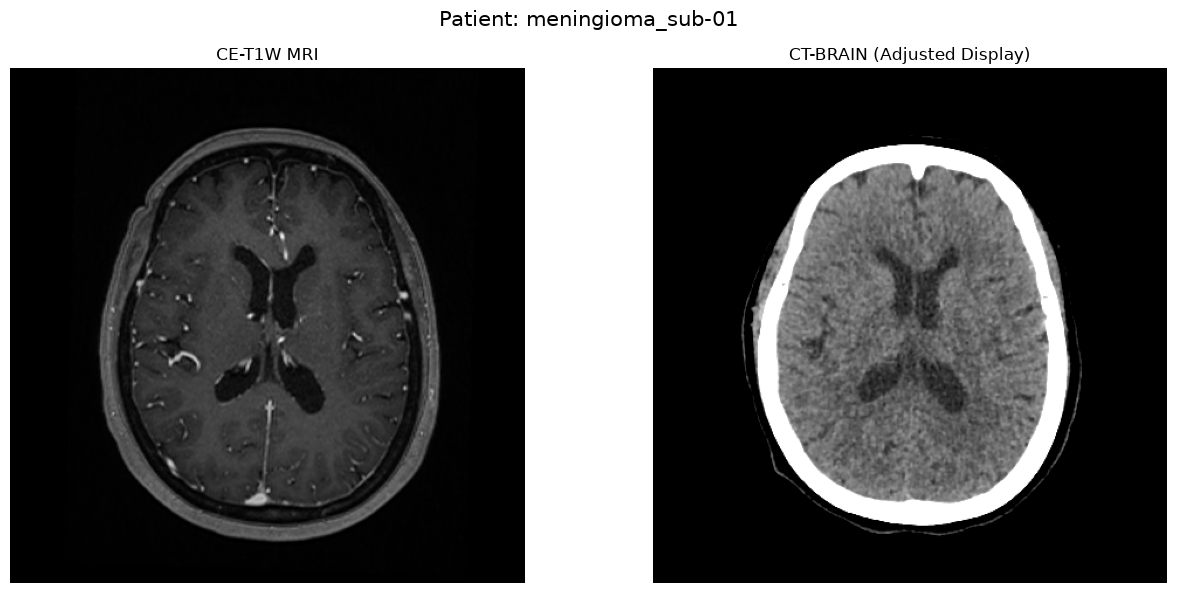

In [54]:
import nibabel as nib
import matplotlib.pyplot as plt

# Select the first patient
patient = master_df.iloc[0]

# Load MRI and CT images
mri_img = nib.load(patient["CE-T1W MRI"])
ct_img = nib.load(patient["CT-BRAIN"])

mri_data = mri_img.get_fdata()
ct_data = ct_img.get_fdata()

# Extract middle slices
mri_slice = mri_data[:, :, mri_data.shape[2] // 2]
ct_slice = ct_data[:, :, ct_data.shape[2] // 2]

# Create side-by-side plots
fig, axes = plt.subplots(1, 2, figsize=(13, 6))

# Display MRI
axes[0].imshow(
    mri_slice.T,
    cmap="gray",
    origin="lower"
)
axes[0].set_title("CE-T1W MRI")
axes[0].axis("off")

# Display CT with adjusted intensity window
axes[1].imshow(
    ct_slice.T,
    cmap="gray",
    origin="lower",
    vmin=-20,
    vmax=100
)
axes[1].set_title("CT-BRAIN (Adjusted Display)")
axes[1].axis("off")

# Add patient ID
plt.suptitle(
    f"Patient: {patient['Unique Patient ID']}",
    fontsize=15
)

plt.tight_layout()
plt.show()

In [55]:
import nibabel as nib
import numpy as np
import pandas as pd

affine_records = []

for _, row in master_df.iterrows():

    # Load MRI and CT
    mri_img = nib.load(row["CE-T1W MRI"])
    ct_img = nib.load(row["CT-BRAIN"])

    # Compare affine matrices
    affine_match = np.allclose(
        mri_img.affine,
        ct_img.affine,
        atol=1e-4
    )

    # Calculate difference between matrices
    max_difference = np.max(
        np.abs(mri_img.affine - ct_img.affine)
    )

    affine_records.append({
        "Patient ID": row["Unique Patient ID"],
        "Diagnosis": row["Diagnosis"],
        "Affine Match": affine_match,
        "Maximum Difference": max_difference
    })

affine_df = pd.DataFrame(affine_records)

print("Total patient pairs checked:", len(affine_df))
print("Matching affine matrices:", affine_df["Affine Match"].sum())
print("Different affine matrices:", (~affine_df["Affine Match"]).sum())

print("\nAffine comparison results:")
print(affine_df.to_string(index=False))

Total patient pairs checked: 100
Matching affine matrices: 98
Different affine matrices: 2

Affine comparison results:
                  Patient ID             Diagnosis  Affine Match  Maximum Difference
           meningioma_sub-01            meningioma          True                 0.0
           meningioma_sub-02            meningioma          True                 0.0
           meningioma_sub-03            meningioma          True                 0.0
           meningioma_sub-04            meningioma          True                 0.0
           meningioma_sub-05            meningioma          True                 0.0
           meningioma_sub-06            meningioma          True                 0.0
           meningioma_sub-07            meningioma          True                 0.0
           meningioma_sub-08            meningioma          True                 0.0
           meningioma_sub-09            meningioma          True                 0.0
           meningioma_sub-10   

In [56]:
# Identify patients with different affine matrices

problem_patients = affine_df[
    affine_df["Affine Match"] == False
]["Patient ID"].tolist()

print("Patients requiring investigation:")
print(problem_patients)

# Display detailed geometry information

for patient_id in problem_patients:

    row = master_df[
        master_df["Unique Patient ID"] == patient_id
    ].iloc[0]

    mri_img = nib.load(row["CE-T1W MRI"])
    ct_img = nib.load(row["CT-BRAIN"])

    print("\n" + "="*60)
    print("PATIENT:", patient_id)

    print("\nMRI shape:")
    print(mri_img.shape)

    print("\nCT shape:")
    print(ct_img.shape)

    print("\nMRI orientation:")
    print(nib.aff2axcodes(mri_img.affine))

    print("\nCT orientation:")
    print(nib.aff2axcodes(ct_img.affine))

    print("\nMRI affine:")
    print(mri_img.affine)

    print("\nCT affine:")
    print(ct_img.affine)

    print("\nMRI voxel spacing:")
    print(nib.affines.voxel_sizes(mri_img.affine))

    print("\nCT voxel spacing:")
    print(nib.affines.voxel_sizes(ct_img.affine))

Patients requiring investigation:
['pituitary tumor_sub-25', 'pituitary tumor_sub-41']

PATIENT: pituitary tumor_sub-25

MRI shape:
(500, 500, 317)

CT shape:
(500, 500, 317)

MRI orientation:
('L', 'A', 'S')

CT orientation:
('L', 'A', 'I')

MRI affine:
[[  -0.5          -0.            0.          134.        ]
 [  -0.            0.5          -0.         -284.11172485]
 [   0.            0.            0.5        -178.94599915]
 [   0.            0.            0.            1.        ]]

CT affine:
[[  -0.5          -0.           -0.          134.        ]
 [  -0.            0.5           0.         -284.11172485]
 [   0.            0.           -0.5         -20.94599915]
 [   0.            0.            0.            1.        ]]

MRI voxel spacing:
[0.5 0.5 0.5]

CT voxel spacing:
[0.5 0.5 0.5]

PATIENT: pituitary tumor_sub-41

MRI shape:
(500, 500, 319)

CT shape:
(500, 500, 319)

MRI orientation:
('L', 'A', 'S')

CT orientation:
('L', 'A', 'I')

MRI affine:
[[  -0.5          -0.   

In [57]:
orientation_records = []

for _, row in master_df.iterrows():

    mri_img = nib.load(row["CE-T1W MRI"])
    ct_img = nib.load(row["CT-BRAIN"])

    # Original orientations
    mri_original = nib.aff2axcodes(mri_img.affine)
    ct_original = nib.aff2axcodes(ct_img.affine)

    # Convert to canonical orientation
    mri_canonical = nib.as_closest_canonical(mri_img)
    ct_canonical = nib.as_closest_canonical(ct_img)

    # New orientations
    mri_new = nib.aff2axcodes(mri_canonical.affine)
    ct_new = nib.aff2axcodes(ct_canonical.affine)

    orientation_records.append({
        "Patient ID": row["Unique Patient ID"],
        "MRI Original": "".join(mri_original),
        "CT Original": "".join(ct_original),
        "MRI Canonical": "".join(mri_new),
        "CT Canonical": "".join(ct_new),
        "Canonical Match": mri_new == ct_new
    })

orientation_df = pd.DataFrame(orientation_records)

print("Total patients:", len(orientation_df))
print(
    "Matching canonical orientations:",
    orientation_df["Canonical Match"].sum()
)
print(
    "Non-matching canonical orientations:",
    (~orientation_df["Canonical Match"]).sum()
)

display(orientation_df[
    orientation_df["Canonical Match"] == False
])

Total patients: 100
Matching canonical orientations: 100
Non-matching canonical orientations: 0


,Patient ID,MRI Original,CT Original,MRI Canonical,CT Canonical,Canonical Match


In [58]:
canonical_affine_records = []

for _, row in master_df.iterrows():

    mri_img = nib.load(row["CE-T1W MRI"])
    ct_img = nib.load(row["CT-BRAIN"])

    mri_canonical = nib.as_closest_canonical(mri_img)
    ct_canonical = nib.as_closest_canonical(ct_img)

    affine_match = np.allclose(
        mri_canonical.affine,
        ct_canonical.affine,
        atol=1e-4
    )

    max_difference = np.max(
        np.abs(
            mri_canonical.affine - ct_canonical.affine
        )
    )

    canonical_affine_records.append({
        "Patient ID": row["Unique Patient ID"],
        "Diagnosis": row["Diagnosis"],
        "Affine Match": affine_match,
        "Maximum Difference": max_difference
    })

canonical_affine_df = pd.DataFrame(canonical_affine_records)

print("Total pairs:", len(canonical_affine_df))
print("Matching affine matrices:",
      canonical_affine_df["Affine Match"].sum())
print("Different affine matrices:",
      (~canonical_affine_df["Affine Match"]).sum())

Total pairs: 100
Matching affine matrices: 100
Different affine matrices: 0


Patient: meningioma_sub-01
MRI shape: (440, 440, 381) Slice: 190
CT shape: (440, 440, 381) Slice: 190


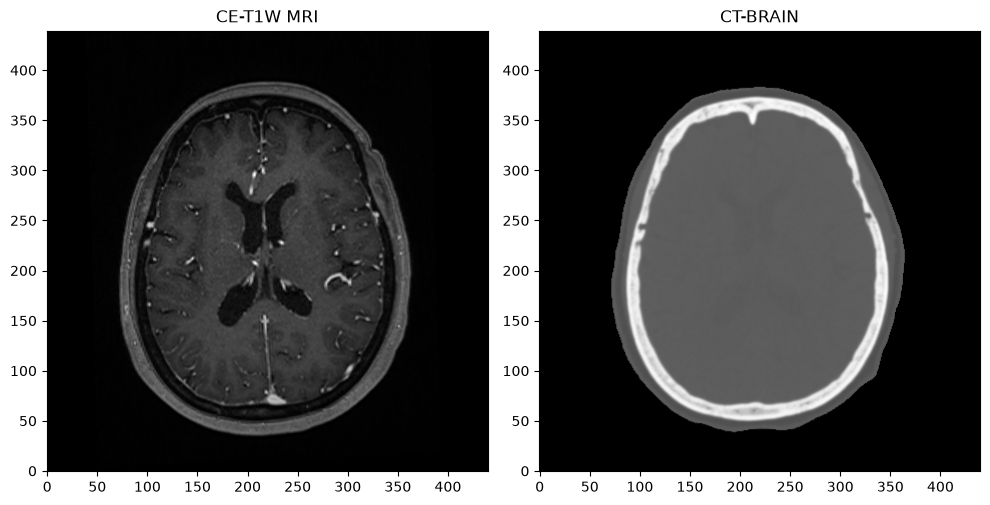

In [59]:
def load_canonical_slice(file_path):

    img = nib.load(file_path)

    # Standardise orientation
    img = nib.as_closest_canonical(img)

    # Load image data
    data = img.get_fdata(dtype=np.float32)

    # Extract middle axial slice
    middle_index = data.shape[2] // 2
    slice_2d = data[:, :, middle_index]

    return slice_2d, img.shape, middle_index


# Test on the first patient
row = master_df.iloc[0]

mri_slice, mri_shape, mri_index = load_canonical_slice(
    row["CE-T1W MRI"]
)

ct_slice, ct_shape, ct_index = load_canonical_slice(
    row["CT-BRAIN"]
)

print("Patient:", row["Unique Patient ID"])
print("MRI shape:", mri_shape, "Slice:", mri_index)
print("CT shape:", ct_shape, "Slice:", ct_index)

# Display both slices
fig, axes = plt.subplots(1, 2, figsize=(10, 5))

axes[0].imshow(mri_slice.T, cmap="gray", origin="lower")
axes[0].set_title("CE-T1W MRI")

axes[1].imshow(ct_slice.T, cmap="gray", origin="lower")
axes[1].set_title("CT-BRAIN")

plt.tight_layout()
plt.show()

In [60]:
import nibabel as nib
import numpy as np
import pandas as pd
import gc

mri_slice_records = []

for _, row in master_df.iterrows():

    img = nib.load(row["CE-T1W MRI"])

    # Get orientation transformation without loading full image
    original_orientation = nib.orientations.io_orientation(
        img.affine
    )

    canonical_orientation = nib.orientations.axcodes2ornt(
        ("R", "A", "S")
    )

    transform = nib.orientations.ornt_transform(
        original_orientation,
        canonical_orientation
    )

    # Find which original axis corresponds to canonical Z
    z_axis = int(
        np.where(transform[:, 0] == 2)[0][0]
    )

    # Determine the direction of the Z axis
    z_direction = transform[z_axis, 1]

    depth = img.shape[z_axis]

    # Select five slices between 25% and 75%
    indices = np.linspace(
        int(depth * 0.25),
        int(depth * 0.75),
        5,
        dtype=int
    )

    for index in indices:

        original_index = (
            index if z_direction == 1
            else depth - 1 - index
        )

        slicer = [slice(None)] * 3
        slicer[z_axis] = original_index

        # Load only one 2D slice
        slice_2d = np.asarray(
            img.dataobj[tuple(slicer)],
            dtype=np.float32
        )

        # Reorient the 2D slice axes
        remaining_axes = [
            axis for axis in range(3)
            if axis != z_axis
        ]

        axis_order = [
            remaining_axes.index(
                int(transform[:, 0][axis])
            )
            for axis in range(3)
            if axis != z_axis
        ]

        if axis_order != [0, 1]:
            slice_2d = np.transpose(
                slice_2d, axis_order
            )

        for axis in range(2):
            original_axis = remaining_axes[axis]

            if transform[original_axis, 1] == -1:
                slice_2d = np.flip(
                    slice_2d, axis=axis
                )

        mri_slice_records.append({
            "Patient ID": row["Unique Patient ID"],
            "Diagnosis": row["Diagnosis"],
            "Slice Index": index,
            "Image": slice_2d.copy()
        })

    del img
    gc.collect()

mri_slices_df = pd.DataFrame(mri_slice_records)

print("Total MRI slices:", len(mri_slices_df))
print("Unique patients:", mri_slices_df["Patient ID"].nunique())

print("\nSlices per diagnosis:")
print(mri_slices_df.groupby("Diagnosis").size())

Total MRI slices: 500
Unique patients: 100

Slices per diagnosis:
Diagnosis
meningioma               100
pituitary tumor          300
vestibular schwannoma    100
dtype: int64


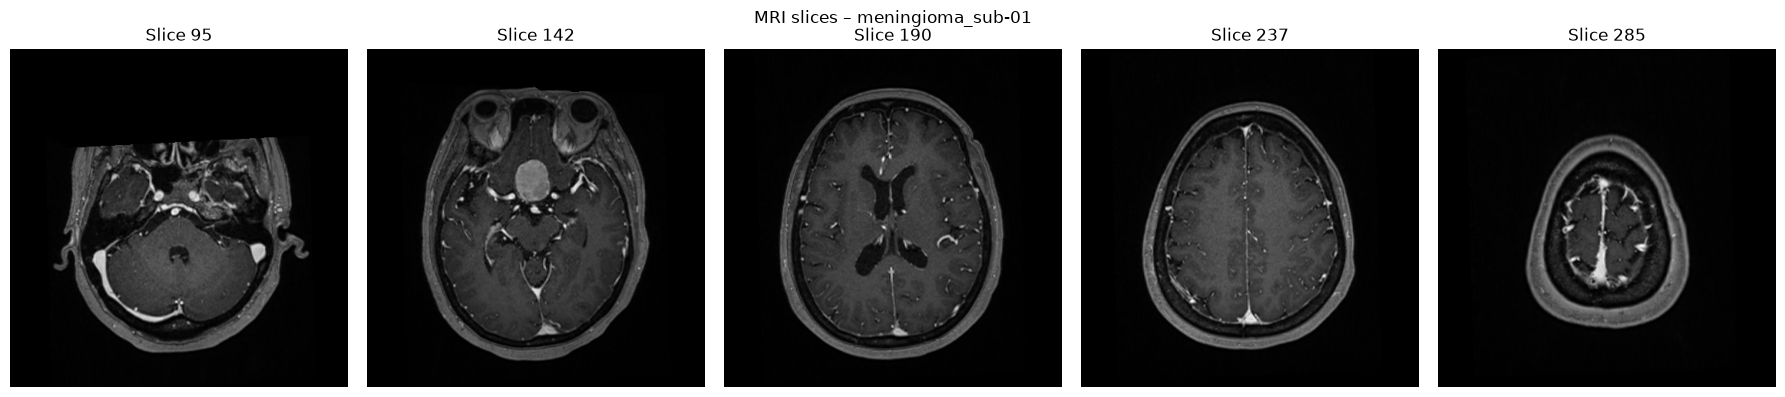

In [61]:
# Display five extracted MRI slices from one patient

patient_id = mri_slices_df["Patient ID"].iloc[0]

patient_slices = mri_slices_df[
    mri_slices_df["Patient ID"] == patient_id
]

fig, axes = plt.subplots(1, 5, figsize=(18, 4))

for ax, (_, row) in zip(axes, patient_slices.iterrows()):

    ax.imshow(
        row["Image"].T,
        cmap="gray",
        origin="lower"
    )

    ax.set_title(f"Slice {row['Slice Index']}")
    ax.axis("off")

plt.suptitle(f"MRI slices – {patient_id}")
plt.tight_layout()
plt.show()

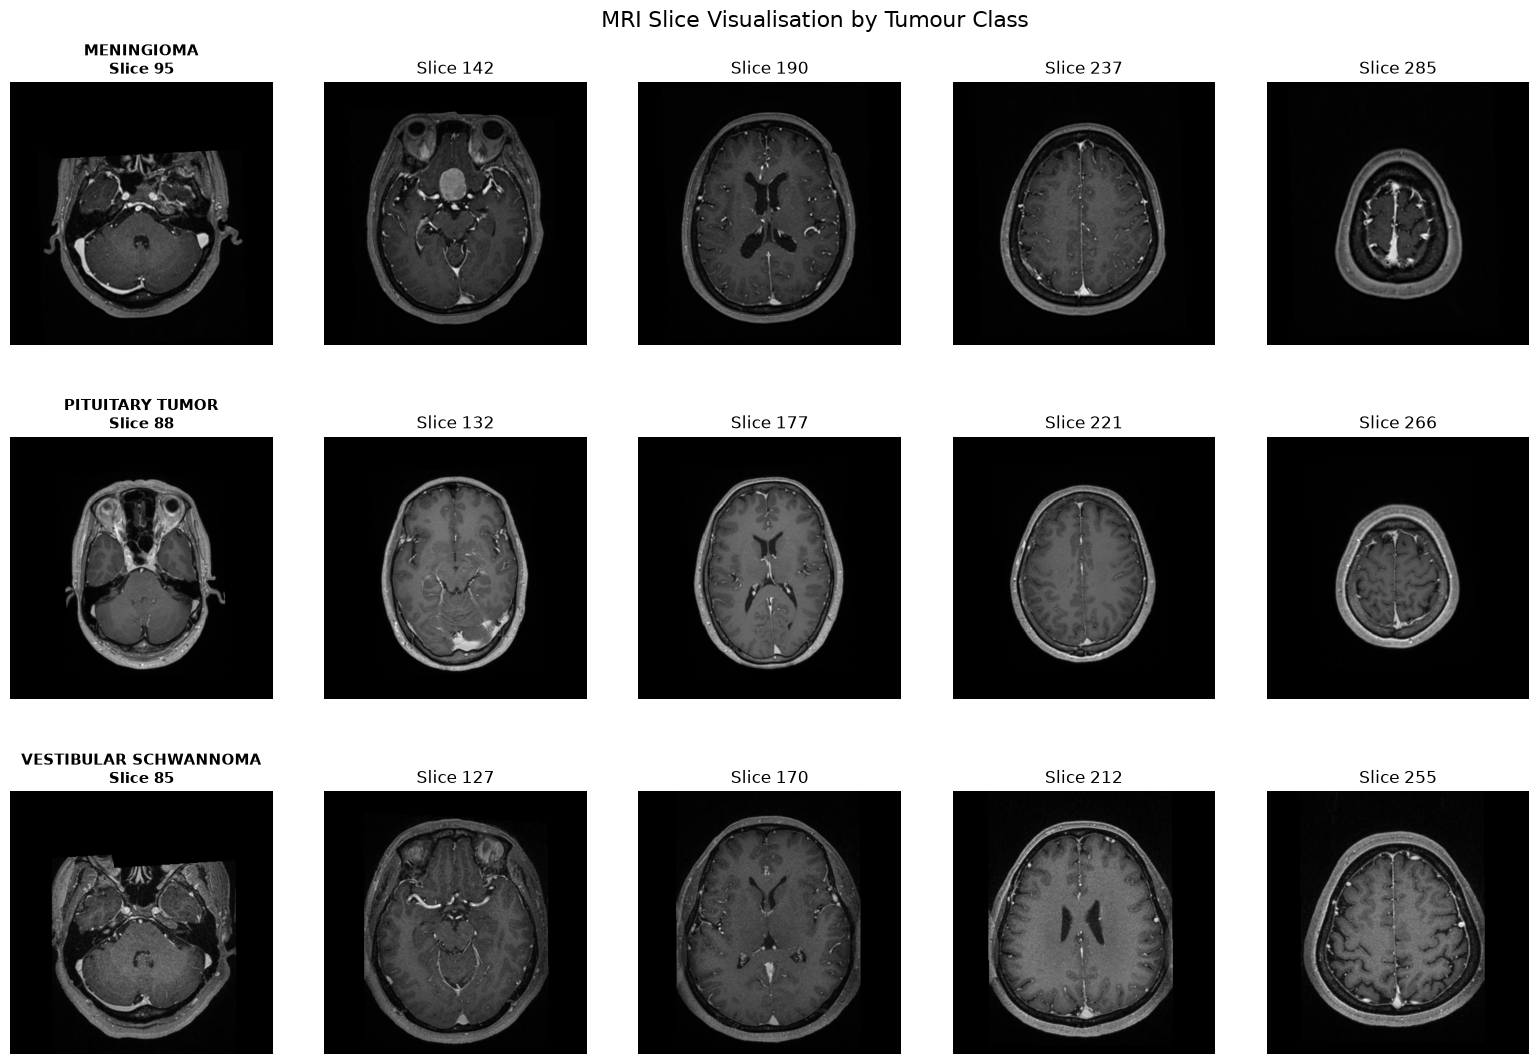

In [62]:
selected_patients = [
    "meningioma_sub-01",
    "pituitary tumor_sub-01",
    "vestibular schwannoma_sub-01"
]

fig, axes = plt.subplots(3, 5, figsize=(18, 12))

for i, patient_id in enumerate(selected_patients):

    patient_data = mri_slices_df[
        mri_slices_df["Patient ID"] == patient_id
    ]

    diagnosis = patient_data["Diagnosis"].iloc[0]

    for j, (_, row) in enumerate(patient_data.iterrows()):

        axes[i, j].imshow(
            row["Image"].T,
            cmap="gray",
            origin="lower"
        )

        axes[i, j].set_title(
            f"Slice {row['Slice Index']}"
        )

        axes[i, j].axis("off")

    # Add tumour class label above the first image
    axes[i, 0].set_title(
        f"{diagnosis.upper()}\nSlice {patient_data.iloc[0]['Slice Index']}",
        fontsize=11,
        fontweight="bold"
    )

fig.suptitle(
    "MRI Slice Visualisation by Tumour Class",
    fontsize=16
)

plt.subplots_adjust(
    left=0.05,
    top=0.92,
    hspace=0.35,
    wspace=0.15
)

plt.show()

In [63]:
# plots and summary statistics; save useful figures for the report, e.g.
# fig, ax = plt.subplots(); ...; fig.savefig(FIG_DIR / "eda_class_balance.png", dpi=300, bbox_inches="tight")

# Method and artefact
*FPR: Methodology*

This section describes the methodology selected for developing a deep-learning model for brain tumour classification using MRI and CT images. The project focuses on three tumour classes: meningioma, pituitary tumour and vestibular schwannoma.

The proposed approach uses 2D convolutional neural networks (CNNs) to investigate the classification performance of individual imaging modalities and their combination. MRI-only and CT-only models will be developed as baseline experiments. A multimodal CNN will then be developed to combine information extracted from both imaging modalities.

The performance of these approaches will be compared to investigate whether combining MRI and CT images improves brain tumour classification.

**Why this method?**

Deep learning is selected because it can automatically learn relevant features from medical images. Convolutional neural networks (CNNs) are commonly used for image classification and can learn spatial patterns from image data.

A 2D CNN approach is selected instead of a 3D CNN because it is more computationally manageable for the available dataset of 100 patients. A 3D CNN uses complete image volumes and can preserve volumetric information, but it generally requires more memory and computational resources.

Vision Transformers are another approach for image classification. However, a CNN provides a simpler starting architecture for this project, allowing baseline experiments to be developed and evaluated before investigating multimodal learning.

MRI and CT are selected because they provide different types of information about brain structures. Using both modalities may provide complementary information that could improve classification performance.

Feature-level fusion is proposed because it allows features to be extracted separately from MRI and CT images before combining them for classification.

**Literature-Based Method Comparison**

The following research approaches will be considered when selecting the methodology for this project:

| Research approach | Main method | Relevance to this project |
|---|---|---|
| MBTC-Net (2025) | EfficientNetV2B0 with a multi-head attention mechanism | Provides an example of deep-learning approaches involving CT and MRI images. |
| Tumnet (2024) | CNN architecture with pixel-level fusion | Provides an example of combining MRI and CT information. |
| Tummala et al. (2022) | Vision Transformer ensemble | Provides an alternative approach for MRI-based tumour classification. |
| Chakrabarty et al. (2021) | 3D convolutional neural network | Provides an example of volumetric MRI-based tumour classification. |

These approaches provide a basis for comparing different image-classification architectures and multimodal techniques. The proposed project will investigate a 2D CNN approach with feature-level fusion using paired MRI and CT images.

**Selected Proposed Approach**

The project will investigate three experimental approaches:

1. **MRI-only classification:** A 2D CNN will use contrast-enhanced T1-weighted MRI (CE-T1W) images to classify the three tumour types.
2. **CT-only classification:** A 2D CNN will use brain CT (CT-BRAIN) images to classify the three tumour types.
3. **Multimodal classification:** A two-branch CNN will process MRI and CT images separately. The extracted features will be combined using feature-level fusion before the final classification layer.

The multimodal model will be the main proposed artefact. Its performance will be compared with the MRI-only and CT-only baseline models.

The classification output will contain three classes: meningioma, pituitary tumour and vestibular schwannoma.

**Baseline**

Baseline models will be developed to establish reference classification performance before implementing the proposed multimodal approach.

Two separate 2D CNN baseline models will be investigated. The first model will use MRI images, while the second model will use CT images. Both models will perform three-class tumour classification.

The baseline results will provide a reference for evaluating whether combining MRI and CT information improves classification performance.

In [64]:
from sklearn.model_selection import train_test_split

# Keep one row per patient
patients_df = master_df.copy()

# Split 70% for training and 30% for validation/testing
train_patients, remaining_patients = train_test_split(
    patients_df,
    test_size=0.30,
    stratify=patients_df["Diagnosis"],
    random_state=42
)

# Split the remaining 30% equally
val_patients, test_patients = train_test_split(
    remaining_patients,
    test_size=0.50,
    stratify=remaining_patients["Diagnosis"],
    random_state=42
)

# Display split sizes
print("Training patients:", len(train_patients))
print("Validation patients:", len(val_patients))
print("Testing patients:", len(test_patients))

# Check class distribution
print("\nTraining class distribution:")
print(train_patients["Diagnosis"].value_counts())

print("\nValidation class distribution:")
print(val_patients["Diagnosis"].value_counts())

print("\nTesting class distribution:")
print(test_patients["Diagnosis"].value_counts())

Training patients: 70
Validation patients: 15
Testing patients: 15

Training class distribution:
Diagnosis
pituitary tumor          42
vestibular schwannoma    14
meningioma               14
Name: count, dtype: int64

Validation class distribution:
Diagnosis
pituitary tumor          9
meningioma               3
vestibular schwannoma    3
Name: count, dtype: int64

Testing class distribution:
Diagnosis
pituitary tumor          9
meningioma               3
vestibular schwannoma    3
Name: count, dtype: int64


In [73]:
# Check for patient overlap between datasets

train_ids = set(train_patients["Unique Patient ID"])
val_ids = set(val_patients["Unique Patient ID"])
test_ids = set(test_patients["Unique Patient ID"])

print("Training and validation overlap:", len(train_ids & val_ids))
print("Training and testing overlap:", len(train_ids & test_ids))
print("Validation and testing overlap:", len(val_ids & test_ids))

Training and validation overlap: 0
Training and testing overlap: 0
Validation and testing overlap: 0


### MRI-Only CNN Baseline

The first baseline experiment (E01) will use contrast-enhanced T1-weighted MRI (CE-T1W) images.

A simple 2D convolutional neural network will be developed to learn image features and classify the images into three tumour categories: meningioma, pituitary tumour and vestibular schwannoma.

The model will establish the classification performance obtained using MRI information alone.

In [75]:
# Extract MRI file paths for each patient split

train_mri_paths = train_patients["CE-T1W MRI"].tolist()
val_mri_paths = val_patients["CE-T1W MRI"].tolist()
test_mri_paths = test_patients["CE-T1W MRI"].tolist()

print("Training MRI files:", len(train_mri_paths))
print("Validation MRI files:", len(val_mri_paths))
print("Testing MRI files:", len(test_mri_paths))

Training MRI files: 70
Validation MRI files: 15
Testing MRI files: 15


MRI dimensions: (500, 500, 299)


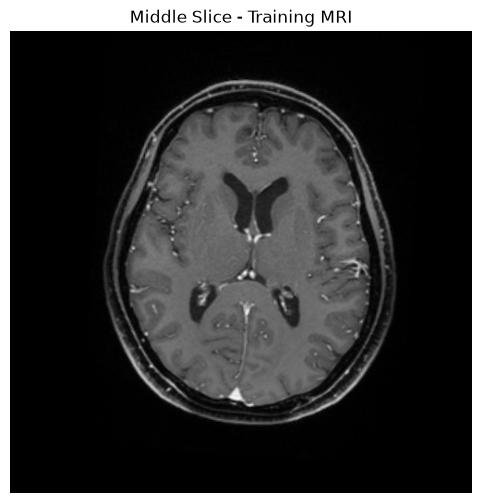

In [76]:
import nibabel as nib
import matplotlib.pyplot as plt

# Load the first training patient's MRI
sample_mri = nib.load(train_mri_paths[0])

# Get image dimensions
print("MRI dimensions:", sample_mri.shape)

# Select the middle slice
middle_index = sample_mri.shape[2] // 2

# Load only the selected slice
mri_slice = np.asarray(sample_mri.dataobj[:, :, middle_index])

# Display the MRI slice
plt.figure(figsize=(6, 6))
plt.imshow(mri_slice.T, cmap="gray", origin="lower")
plt.title("Middle Slice - Training MRI")
plt.axis("off")
plt.show()

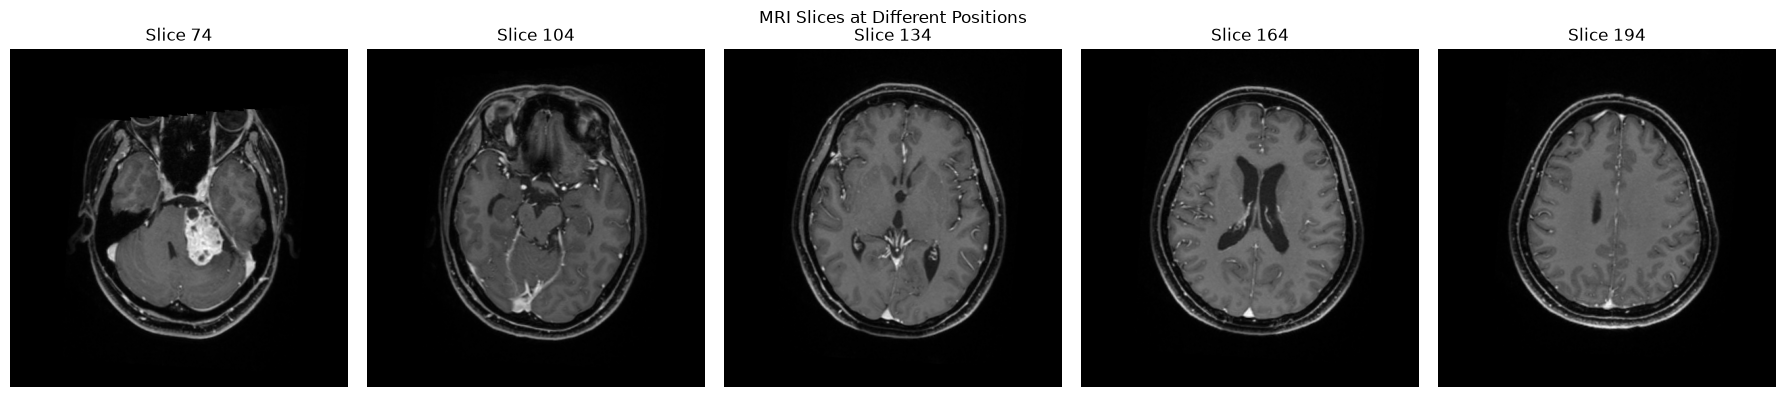

In [77]:
# Select five slices from different positions
depth = sample_mri.shape[2]

slice_indices = [
    int(depth * 0.25),
    int(depth * 0.35),
    int(depth * 0.45),
    int(depth * 0.55),
    int(depth * 0.65)
]

# Display the five slices
fig, axes = plt.subplots(1, 5, figsize=(18, 4))

for ax, index in zip(axes, slice_indices):
    image = np.asarray(sample_mri.dataobj[:, :, index])

    ax.imshow(image.T, cmap="gray", origin="lower")
    ax.set_title(f"Slice {index}")
    ax.axis("off")

plt.suptitle("MRI Slices at Different Positions")
plt.tight_layout()
plt.show()

In [78]:
# Check dimensions of the five selected MRI slices

for index in slice_indices:
    image = np.asarray(sample_mri.dataobj[:, :, index])

    print(f"Slice {index}: {image.shape}")

Slice 74: (500, 500)
Slice 104: (500, 500)
Slice 134: (500, 500)
Slice 164: (500, 500)
Slice 194: (500, 500)


In [79]:
# Check intensity statistics of the five MRI slices

for index in slice_indices:
    image = np.asarray(
        sample_mri.dataobj[:, :, index],
        dtype=np.float32
    )

    print(f"\nSlice {index}")
    print("Minimum:", np.min(image))
    print("Maximum:", np.max(image))
    print("Mean:", np.mean(image))
    print("Standard deviation:", np.std(image))


Slice 74
Minimum: 0.0
Maximum: 935.4203
Mean: 85.37418
Standard deviation: 152.37631

Slice 104
Minimum: 0.0
Maximum: 1078.4486
Mean: 105.39532
Standard deviation: 153.42809

Slice 134
Minimum: 0.0
Maximum: 917.87585
Mean: 108.83895
Standard deviation: 153.51321

Slice 164
Minimum: 0.0
Maximum: 856.0037
Mean: 100.60163
Standard deviation: 146.80107

Slice 194
Minimum: 0.0
Maximum: 887.8838
Mean: 97.482574
Standard deviation: 149.75566


In [83]:
%pip install scikit-image


Note: you may need to restart the kernel to use updated packages.


In [84]:
from skimage.transform import resize

# Select one MRI slice
image = np.asarray(
    sample_mri.dataobj[:, :, middle_index],
    dtype=np.float32
)

# Resize to 128 × 128
resized_image = resize(
    image,
    (128, 128),
    preserve_range=True,
    anti_aliasing=True
)

# Min-max normalisation
normalised_image = (
    resized_image - resized_image.min()
) / (
    resized_image.max() - resized_image.min() + 1e-8
)

print("Original shape:", image.shape)
print("Resized shape:", normalised_image.shape)
print("Minimum intensity:", normalised_image.min())
print("Maximum intensity:", normalised_image.max())

Original shape: (500, 500)
Resized shape: (128, 128)
Minimum intensity: 0.0
Maximum intensity: 1.0


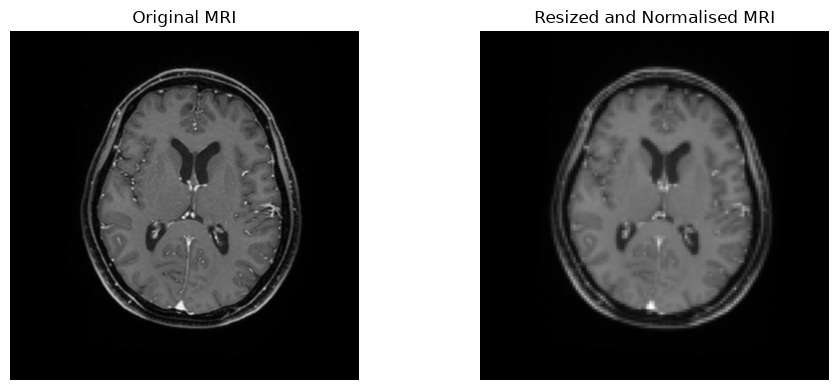

In [85]:
plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.imshow(image.T, cmap="gray", origin="lower")
plt.title("Original MRI")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(normalised_image.T, cmap="gray", origin="lower")
plt.title("Resized and Normalised MRI")
plt.axis("off")

plt.tight_layout()
plt.show()

In [86]:
# Load CT-BRAIN for the same patient

sample_ct = nib.load(
    train_patients.iloc[0]["CT-BRAIN"]
)

print("MRI dimensions:", sample_mri.shape)
print("CT dimensions:", sample_ct.shape)

print(
    "MRI canonical orientation:",
    nib.aff2axcodes(nib.as_closest_canonical(sample_mri).affine)
)

print(
    "CT canonical orientation:",
    nib.aff2axcodes(nib.as_closest_canonical(sample_ct).affine)
)

MRI dimensions: (500, 500, 299)
CT dimensions: (500, 500, 299)
MRI canonical orientation: ('R', 'A', 'S')
CT canonical orientation: ('R', 'A', 'S')


In [87]:
# Convert both images to canonical orientation
mri_canonical = nib.as_closest_canonical(sample_mri)
ct_canonical = nib.as_closest_canonical(sample_ct)

# Compare affine matrices
print(
    "MRI and CT affine matrices match:",
    np.allclose(mri_canonical.affine, ct_canonical.affine)
)

# Calculate maximum difference
affine_difference = np.max(
    np.abs(mri_canonical.affine - ct_canonical.affine)
)

print("Maximum affine difference:", affine_difference)

MRI and CT affine matrices match: True
Maximum affine difference: 0.0


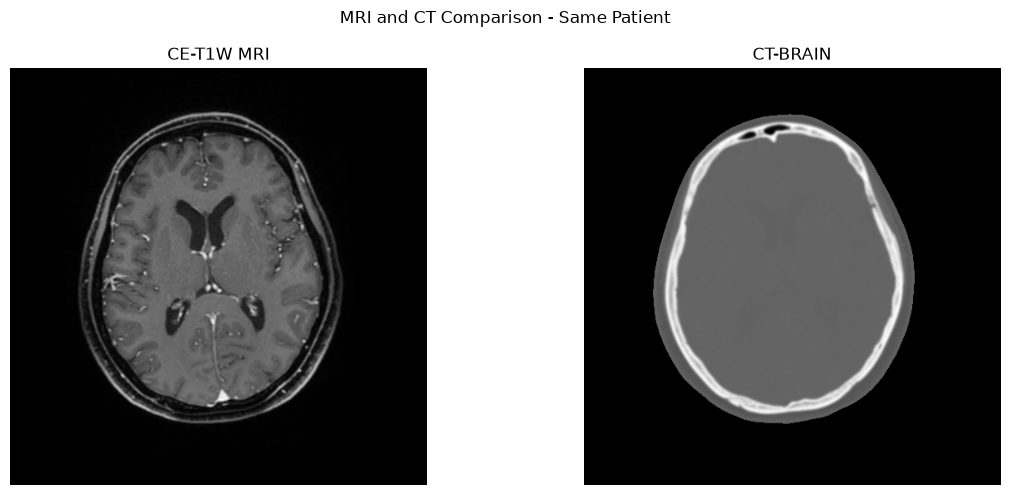

In [88]:
# Select the middle slice from both canonical images
middle_index = mri_canonical.shape[2] // 2

mri_slice = np.asarray(
    mri_canonical.dataobj[:, :, middle_index],
    dtype=np.float32
)

ct_slice = np.asarray(
    ct_canonical.dataobj[:, :, middle_index],
    dtype=np.float32
)

# Display MRI and CT side by side
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].imshow(mri_slice.T, cmap="gray", origin="lower")
axes[0].set_title("CE-T1W MRI")
axes[0].axis("off")

axes[1].imshow(ct_slice.T, cmap="gray", origin="lower")
axes[1].set_title("CT-BRAIN")
axes[1].axis("off")

plt.suptitle("MRI and CT Comparison - Same Patient")
plt.tight_layout()
plt.show()

In [90]:
def prepare_mri_dataset(patient_df, target_size=(128, 128)):

    images = []
    labels = []
    patient_ids = []

    slice_positions = [0.25, 0.35, 0.45, 0.55, 0.65]

    for _, row in patient_df.iterrows():

        img = nib.load(row["CE-T1W MRI"])
        img = nib.as_closest_canonical(img)

        depth = img.shape[2]

        for position in slice_positions:

            index = int(depth * position)

            slice_image = np.asarray(
                img.dataobj[:, :, index],
                dtype=np.float32
            )

            resized = resize(
                slice_image,
                target_size,
                preserve_range=True,
                anti_aliasing=True
            )

            normalised = (
                resized - resized.min()
            ) / (
                resized.max() - resized.min() + 1e-8
            )

            images.append(normalised[..., np.newaxis])
            labels.append(row["Diagnosis"])
            patient_ids.append(row["Unique Patient ID"])

    return (
        np.array(images, dtype=np.float32),
        np.array(labels),
        np.array(patient_ids)
    )

In [91]:
X_train_mri, y_train_mri, train_mri_ids = prepare_mri_dataset(train_patients)

X_val_mri, y_val_mri, val_mri_ids = prepare_mri_dataset(val_patients)

X_test_mri, y_test_mri, test_mri_ids = prepare_mri_dataset(test_patients)

print("Training MRI shape:", X_train_mri.shape)
print("Validation MRI shape:", X_val_mri.shape)
print("Testing MRI shape:", X_test_mri.shape)

Training MRI shape: (350, 128, 128, 1)
Validation MRI shape: (75, 128, 128, 1)
Testing MRI shape: (75, 128, 128, 1)


In [92]:
from sklearn.preprocessing import LabelEncoder

# Create label encoder
label_encoder = LabelEncoder()

# Fit using training labels and transform all datasets
y_train_mri_encoded = label_encoder.fit_transform(y_train_mri)
y_val_mri_encoded = label_encoder.transform(y_val_mri)
y_test_mri_encoded = label_encoder.transform(y_test_mri)

# Display class mapping
print("Tumour class mapping:")

for index, tumour in enumerate(label_encoder.classes_):
    print(tumour, ":", index)

# Check encoded label shapes
print("\nTraining labels:", y_train_mri_encoded.shape)
print("Validation labels:", y_val_mri_encoded.shape)
print("Testing labels:", y_test_mri_encoded.shape)

Tumour class mapping:
meningioma : 0
pituitary tumor : 1
vestibular schwannoma : 2

Training labels: (350,)
Validation labels: (75,)
Testing labels: (75,)


In [93]:
import pandas as pd

# Check the number of slices in each tumour class
print("Training class distribution:")
print(pd.Series(y_train_mri).value_counts())

print("\nValidation class distribution:")
print(pd.Series(y_val_mri).value_counts())

print("\nTesting class distribution:")
print(pd.Series(y_test_mri).value_counts())

Training class distribution:
pituitary tumor          210
vestibular schwannoma     70
meningioma                70
Name: count, dtype: int64

Validation class distribution:
pituitary tumor          45
meningioma               15
vestibular schwannoma    15
Name: count, dtype: int64

Testing class distribution:
pituitary tumor          45
meningioma               15
vestibular schwannoma    15
Name: count, dtype: int64


In [94]:
import tensorflow as tf
from tensorflow.keras import layers, models

# Build MRI-only CNN
mri_model = models.Sequential([
    layers.Input(shape=(128, 128, 1)),

    layers.Conv2D(32, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(64, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(128, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),

    layers.Flatten(),

    layers.Dense(128, activation="relu"),
    layers.Dropout(0.5),

    layers.Dense(3, activation="softmax")
])

# Configure the model
mri_model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

# Display model architecture
mri_model.summary()


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                      │ (None, 126, 126, 32)        │             320 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d (MaxPooling2D)         │ (None, 63, 63, 32)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_1 (Conv2D)                    │ (None, 61, 61, 64)          │          18,496 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_1 (MaxPooling2D)       │ (None, 30, 30, 64)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_2 (Conv2D)                    │ (None, 28, 28, 128)         │          73,856 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_2 (MaxPooling2D)       │ (None, 14, 14, 128)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ flatten (Flatten)                    │ (None, 25088)               │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 128)                 │       3,211,392 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 128)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 3)                   │             387 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 3,304,451 (12.61 MB)

 Trainable params: 3,304,451 (12.61 MB)

 Non-trainable params: 0 (0.00 B)

In [95]:
from sklearn.utils.class_weight import compute_class_weight
import numpy as np

class_weights = compute_class_weight(
    class_weight="balanced",
    classes=np.unique(y_train_mri_encoded),
    y=y_train_mri_encoded
)

class_weights_dict = dict(
    enumerate(class_weights)
)

print("Class weights:")
for class_id, weight in class_weights_dict.items():
    print(label_encoder.classes_[class_id], ":", round(weight, 3))

Class weights:
meningioma : 1.667
pituitary tumor : 0.556
vestibular schwannoma : 1.667


In [96]:
from tensorflow.keras.callbacks import EarlyStopping

early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True
)

print("Early stopping callback is ready.")

Early stopping callback is ready.


In [97]:
history_mri = mri_model.fit(
    X_train_mri,
    y_train_mri_encoded,

    validation_data=(
        X_val_mri,
        y_val_mri_encoded
    ),

    epochs=30,
    batch_size=16,

    class_weight=class_weights_dict,

    callbacks=[early_stopping],

    verbose=1
)

Epoch 1/30
22/22 ━━━━━━━━━━━━━━━━━━━━ 15s 410ms/step - accuracy: 0.4657 - loss: 1.0946 - val_accuracy: 0.5867 - val_loss: 1.0782
Epoch 2/30
22/22 ━━━━━━━━━━━━━━━━━━━━ 8s 288ms/step - accuracy: 0.5600 - loss: 1.0642 - val_accuracy: 0.5467 - val_loss: 1.0023
Epoch 3/30
22/22 ━━━━━━━━━━━━━━━━━━━━ 6s 267ms/step - accuracy: 0.6371 - loss: 1.0342 - val_accuracy: 0.4400 - val_loss: 1.0746
Epoch 4/30
22/22 ━━━━━━━━━━━━━━━━━━━━ 10s 267ms/step - accuracy: 0.4514 - loss: 1.0294 - val_accuracy: 0.3733 - val_loss: 1.1287
Epoch 5/30
22/22 ━━━━━━━━━━━━━━━━━━━━ 10s 267ms/step - accuracy: 0.5686 - loss: 0.9766 - val_accuracy: 0.5467 - val_loss: 0.9808
Epoch 6/30
22/22 ━━━━━━━━━━━━━━━━━━━━ 10s 266ms/step - accuracy: 0.6486 - loss: 0.8649 - val_accuracy: 0.3467 - val_loss: 1.1157
Epoch 7/30
22/22 ━━━━━━━━━━━━━━━━━━━━ 6s 263ms/step - accuracy: 0.6743 - loss: 0.7211 - val_accuracy: 0.4800 - val_loss: 1.1182
Epoch 8/30
22/22 ━━━━━━━━━━━━━━━━━━━━ 10s 269ms/step - accuracy: 0.7457 - loss: 0.6356 - val_accurac

In [98]:
print("Epochs completed:", len(history_mri.history["loss"]))

print("Best validation loss:",
      min(history_mri.history["val_loss"]))

print("Best validation accuracy:",
      max(history_mri.history["val_accuracy"]))

print("Best epoch:",
      np.argmin(history_mri.history["val_loss"]) + 1)

Epochs completed: 10
Best validation loss: 0.9807940721511841
Best validation accuracy: 0.5866666436195374
Best epoch: 5


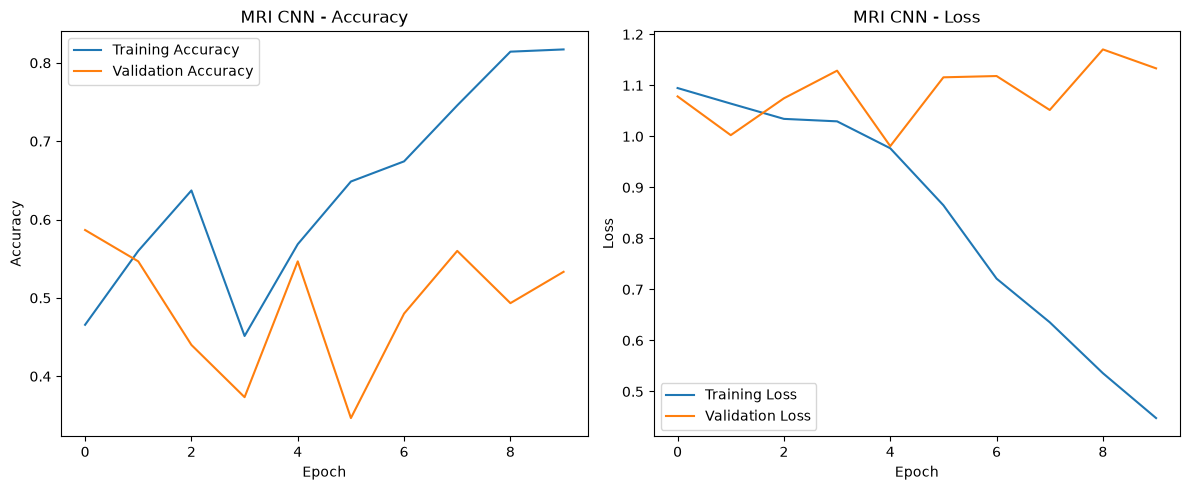

In [99]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))

# Accuracy
plt.subplot(1, 2, 1)
plt.plot(history_mri.history["accuracy"], label="Training Accuracy")
plt.plot(history_mri.history["val_accuracy"], label="Validation Accuracy")
plt.title("MRI CNN - Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()

# Loss
plt.subplot(1, 2, 2)
plt.plot(history_mri.history["loss"], label="Training Loss")
plt.plot(history_mri.history["val_loss"], label="Validation Loss")
plt.title("MRI CNN - Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

plt.tight_layout()
plt.show()

In [100]:
test_loss, test_accuracy = mri_model.evaluate(
    X_test_mri,
    y_test_mri_encoded,
    verbose=1
)

print("MRI Test Loss:", round(test_loss, 4))
print("MRI Test Accuracy:", round(test_accuracy * 100, 2), "%")

3/3 ━━━━━━━━━━━━━━━━━━━━ 1s 174ms/step - accuracy: 0.6533 - loss: 0.8197
MRI Test Loss: 0.8197
MRI Test Accuracy: 65.33 %


3/3 ━━━━━━━━━━━━━━━━━━━━ 1s 347ms/step


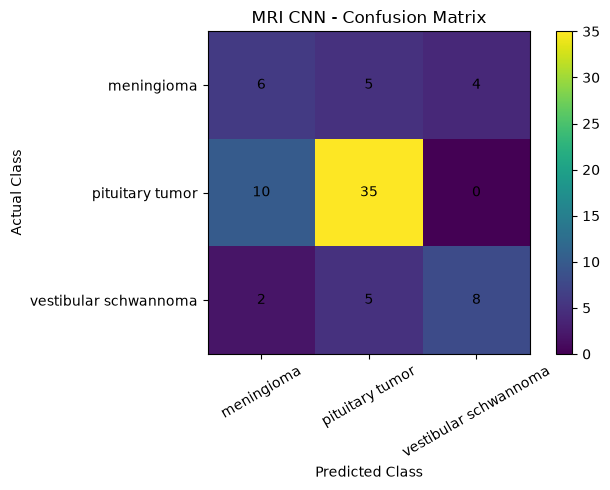

                       precision    recall  f1-score   support

           meningioma       0.33      0.40      0.36        15
      pituitary tumor       0.78      0.78      0.78        45
vestibular schwannoma       0.67      0.53      0.59        15

             accuracy                           0.65        75
            macro avg       0.59      0.57      0.58        75
         weighted avg       0.67      0.65      0.66        75



In [102]:
from sklearn.metrics import confusion_matrix, classification_report
import matplotlib.pyplot as plt
import numpy as np

# Generate predictions
y_pred_prob = mri_model.predict(X_test_mri)

# Convert probabilities into predicted class labels
y_pred_mri = np.argmax(y_pred_prob, axis=1)

# Create confusion matrix
cm = confusion_matrix(
    y_test_mri_encoded,
    y_pred_mri
)

# Display confusion matrix using Matplotlib
plt.figure(figsize=(7, 5))
plt.imshow(cm, interpolation="nearest")
plt.title("MRI CNN - Confusion Matrix")
plt.colorbar()

classes = label_encoder.classes_
positions = np.arange(len(classes))

plt.xticks(positions, classes, rotation=30)
plt.yticks(positions, classes)

for i in range(cm.shape[0]):
    for j in range(cm.shape[1]):
        plt.text(j, i, cm[i, j], ha="center", va="center")

plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.tight_layout()
plt.show()

# Classification report
print(classification_report(
    y_test_mri_encoded,
    y_pred_mri,
    target_names=classes,
    zero_division=0
))

In [103]:
import pandas as pd
import numpy as np
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

# Store slice-level predictions
slice_results = pd.DataFrame({
    "Patient_ID": test_mri_ids,
    "Actual_Label": y_test_mri_encoded,
    "Predicted_Label": y_pred_mri
})

# Add predicted probabilities
for i, class_name in enumerate(label_encoder.classes_):
    slice_results[class_name] = y_pred_prob[:, i]

# Average probabilities for each patient
patient_results = slice_results.groupby("Patient_ID").agg(
    Actual_Label=("Actual_Label", "first"),
    meningioma=("meningioma", "mean"),
    pituitary_tumor=("pituitary tumor", "mean"),
    vestibular_schwannoma=("vestibular schwannoma", "mean")
).reset_index()

# Get patient-level predictions
probability_columns = [
    "meningioma",
    "pituitary_tumor",
    "vestibular_schwannoma"
]

patient_results["Predicted_Label"] = np.argmax(
    patient_results[probability_columns].values,
    axis=1
)

# Evaluate patient-level performance
print("Number of test patients:", len(patient_results))

print("\nPatient-level accuracy:",
      round(accuracy_score(
          patient_results["Actual_Label"],
          patient_results["Predicted_Label"]
      ) * 100, 2), "%")

print("\nPatient-level classification report:")

print(classification_report(
    patient_results["Actual_Label"],
    patient_results["Predicted_Label"],
    target_names=label_encoder.classes_,
    zero_division=0
))

Number of test patients: 15

Patient-level accuracy: 66.67 %

Patient-level classification report:
                       precision    recall  f1-score   support

           meningioma       0.33      0.33      0.33         3
      pituitary tumor       0.70      0.78      0.74         9
vestibular schwannoma       1.00      0.67      0.80         3

             accuracy                           0.67        15
            macro avg       0.68      0.59      0.62        15
         weighted avg       0.69      0.67      0.67        15



### Proposed method / artefact
Build it on its own branch: `git checkout -b proposed-method`

In [65]:
# your main method or artefact (keep functions small and well named, you may be asked to change them live in the demo)

Save your work, then run these commands in the terminal:
```bash
git status
git add .
git commit -m "CODE: baseline and proposed method"
git push
```

# Experiments
*FPR: Quality and Results*


Save your work, then run these commands in the terminal:
```bash
git status
git add .
git commit -m "EXP: E01 baseline, accuracy 0.81"
git push
```

# Testing and validation
*FPR: Methodology (test strategy and validation)*

- **Testing:** check that your code does what you expect (unit tests, edge cases).
- **Validation:** check that your results are reliable (cross-validation, held-out test set, benchmark comparison).

In [66]:
# simple unit tests, e.g.
# assert clean(df).isna().sum().sum() == 0, "cleaned data should have no missing values"
# assert model.predict(X_test).shape[0] == len(X_test)

In [67]:
# validation, e.g. k-fold cross-validation or a held-out test set

Save your work, then run these commands in the terminal:
```bash
git status
git add .
git commit -m "TEST: unit tests and 5-fold cross-validation"
git push
```

# Results
*FPR: Quality and Results*

Save every figure and table you use in the report, then upload them to Overleaf.

In [68]:
# results = pd.read_csv(RESULTS_DIR / "experiments.csv"); display(results)
# results.to_latex(FIG_DIR / "results_table.tex", index=False)   # paste or \input into Overleaf

*What do the results mean? Link them to your objectives and the literature.*

Save your work, then run these commands in the terminal:
```bash
git status
git add .
git commit -m "RESULT: final results table and figures for FPR"
git push
```

# Demo / viva preparation (20%)
About 10 minutes of demo, then about 10 minutes of questions. Focus on the **practical work**: no slides, no reading the report.

**Plan what to show:**
1. Problem and objective (1 min)
2. Data and how you prepared it
3. Your artefact running: run the cell below from a fresh kernel
4. Key results and what they mean

**Practise these questions:**
- What did you do, why, and how? How did you know how to do it?
- What challenges did you meet, and how did you solve them?
- How did your project change over time? (use your commit history)
- Explain this function and change a parameter live. What happens?
- Where could your code be optimised? Show the change.

In [69]:
# DEMO: run the whole pipeline end to end from a fresh kernel (Kernel -> Restart and Run All)
# 1. load data  2. clean  3. train / build  4. evaluate  5. show key figure

# Create your release (before you submit the IPR and FPR)
A **release** is a named snapshot of your work at submission. Your supervisor can open exactly what you submitted, with your PDF attached.

| Milestone | Release name |
|---|---|
| Interim Progress Report (10%) | `IPR-v1.0` |
| Final Project Report (70%) | `FPR-v1.0` |
| Optional: fixes before the demo | `Demo-v1.0` |

**Step 1. Save and push your final work**
```bash
git status
git add .
git commit -m "FPR: final version for submission"
git push
```

**Step 2. Create the release on GitHub**
1. On your repository page, click **Releases** (right-hand side) → **Draft a new release**.
2. Click **Choose a tag**, type `FPR-v1.0` and click **Create new tag**. Target: `main`.
3. **Release title:** *Final Project Report*.
4. **Description** (3–5 lines), for example:
   > Final submission. Includes the full pipeline in MSC_final_project.ipynb, 12 logged experiments and the FPR.
   > Changes since IPR-v1.0: added the proposed method and cross-validation.
   > Known issue: training on the full dataset takes about 2 hours.
5. **Attach files:** drag in your submitted PDF (and for the FPR, your code `.txt`).
6. Click **Publish release**.

**Step 3. Put the release name on your cover page**
In Overleaf: `\gitrelease{FPR-v1.0}`. Then submit on Canvas as normal (Canvas is the official submission).

**Check:** your release now appears under **Releases** on your repository page. Do not delete or edit it after you submit.